In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("AEP_hourly.csv")

# Convert datetime column
df["Datetime"] = pd.to_datetime(df["Datetime"])

# Sort records by date
df = df.sort_values("Datetime").reset_index(drop=True)

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,Datetime,AEP_MW
0,2004-10-01 01:00:00,12379.0
1,2004-10-01 02:00:00,11935.0
2,2004-10-01 03:00:00,11692.0
3,2004-10-01 04:00:00,11597.0
4,2004-10-01 05:00:00,11681.0


In [2]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (121273, 2)

Missing Values:
Datetime    0
AEP_MW      0
dtype: int64

Data Types:
Datetime    datetime64[us]
AEP_MW             float64
dtype: object


In [3]:
# Check duplicate timestamps
duplicate_count = df["Datetime"].duplicated().sum()

# Check time intervals
time_diff = df["Datetime"].diff()

# Count different time intervals
interval_counts = time_diff.value_counts()

print("Duplicate Timestamps:", duplicate_count)

print("\nTime Interval Counts:")
display(interval_counts.head(10))

Duplicate Timestamps: 4

Time Interval Counts:


Datetime
0 days 01:00:00    121241
0 days 02:00:00        27
0 days 00:00:00         4
Name: count, dtype: int64

In [4]:
duplicates = df[
    df["Datetime"].duplicated(keep=False)
].sort_values("Datetime")

print("Duplicate Timestamp Records:")
display(duplicates)

Duplicate Timestamp Records:


,Datetime,AEP_MW
88394,2014-11-02 02:00:00,12994.0
88395,2014-11-02 02:00:00,13190.0
97130,2015-11-01 02:00:00,10785.0
97131,2015-11-01 02:00:00,10542.0
106034,2016-11-06 02:00:00,10964.0
106035,2016-11-06 02:00:00,11008.0
114770,2017-11-05 02:00:00,10596.0
114771,2017-11-05 02:00:00,10446.0


In [5]:
# Find time intervals greater than one hour
time_diff = df["Datetime"].diff()

gap_indices = df.index[time_diff > pd.Timedelta(hours=1)]

gap_details = pd.DataFrame({
    "Previous Datetime": df.loc[gap_indices - 1, "Datetime"].values,
    "Next Datetime": df.loc[gap_indices, "Datetime"].values,
    "Time Gap": time_diff.loc[gap_indices].values
})

print("Missing Hourly Intervals:")
display(gap_details)

Missing Hourly Intervals:


,Previous Datetime,Next Datetime,Time Gap
0,2004-10-31 01:00:00,2004-10-31 03:00:00,0 days 02:00:00
1,2005-04-03 02:00:00,2005-04-03 04:00:00,0 days 02:00:00
2,2005-10-30 01:00:00,2005-10-30 03:00:00,0 days 02:00:00
3,2006-04-02 02:00:00,2006-04-02 04:00:00,0 days 02:00:00
4,2006-10-29 01:00:00,2006-10-29 03:00:00,0 days 02:00:00
5,2007-03-11 02:00:00,2007-03-11 04:00:00,0 days 02:00:00
6,2007-11-04 01:00:00,2007-11-04 03:00:00,0 days 02:00:00
7,2008-03-09 02:00:00,2008-03-09 04:00:00,0 days 02:00:00
8,2008-11-02 01:00:00,2008-11-02 03:00:00,0 days 02:00:00
9,2009-03-08 02:00:00,2009-03-08 04:00:00,0 days 02:00:00


In [6]:
unusual_dates = [
    "2010-12-09 23:00:00",
    "2012-12-06 03:00:00",
    "2014-03-11 13:00:00"
]

for date in unusual_dates:
    current_date = pd.to_datetime(date)

    print("\nRecords around:", date)

    display(
        df[
            (df["Datetime"] >= current_date - pd.Timedelta(hours=2)) &
            (df["Datetime"] <= current_date + pd.Timedelta(hours=4))
        ]
    )


Records around: 2010-12-09 23:00:00


,Datetime,AEP_MW
54247,2010-12-09 21:00:00,20600.0
54248,2010-12-09 22:00:00,20130.0
54249,2010-12-09 23:00:00,19078.0
54250,2010-12-10 01:00:00,17373.0
54251,2010-12-10 02:00:00,17030.0
54252,2010-12-10 03:00:00,16794.0



Records around: 2012-12-06 03:00:00


,Datetime,AEP_MW
71694,2012-12-06 01:00:00,14946.0
71695,2012-12-06 02:00:00,14707.0
71696,2012-12-06 03:00:00,14711.0
71697,2012-12-06 05:00:00,15192.0
71698,2012-12-06 06:00:00,16096.0
71699,2012-12-06 07:00:00,17657.0



Records around: 2014-03-11 13:00:00


,Datetime,AEP_MW
82740,2014-03-11 11:00:00,15548.0
82741,2014-03-11 12:00:00,15032.0
82742,2014-03-11 13:00:00,14839.0
82743,2014-03-11 15:00:00,14405.0
82744,2014-03-11 16:00:00,14132.0
82745,2014-03-11 17:00:00,14125.0


In [7]:
# Keep original data unchanged
raw_df = df.copy()

# Combine duplicate timestamps using mean demand
model_df = (
    raw_df.groupby("Datetime", as_index=False)["AEP_MW"]
    .mean()
)

# Create a complete hourly timeline
model_df = (
    model_df.set_index("Datetime")
    .asfreq("h")
)

print("Original records:", len(raw_df))
print("Records after handling duplicates:", len(model_df))
print("Missing demand values:", model_df["AEP_MW"].isnull().sum())

display(model_df.head())

Original records: 121273
Records after handling duplicates: 121296
Missing demand values: 27


,AEP_MW
Datetime,
2004-10-01 01:00:00,12379.0
2004-10-01 02:00:00,11935.0
2004-10-01 03:00:00,11692.0
2004-10-01 04:00:00,11597.0
2004-10-01 05:00:00,11681.0


In [8]:
# Check time intervals after preprocessing
new_time_diff = model_df.index.to_series().diff()

print("Time Interval Counts:")
display(new_time_diff.value_counts().head())

print("\nMissing Demand Values:")
print(model_df["AEP_MW"].isnull().sum())

print("\nDuplicate Timestamps:")
print(model_df.index.duplicated().sum())

Time Interval Counts:


Datetime
0 days 01:00:00    121295
Name: count, dtype: int64


Missing Demand Values:
27

Duplicate Timestamps:
0


In [10]:
# Extract time-based features
model_df["Hour"] = model_df.index.hour
model_df["Day"] = model_df.index.day_of_week
model_df["Month"] = model_df.index.month
model_df["Day_of_Year"] = model_df.index.day_of_year

model_df["Is_Weekend"] = (
    model_df.index.day_of_week >= 5
).astype(int)

print("Time-based features created successfully!")

display(model_df.head(10))

Time-based features created successfully!


,AEP_MW,Hour,Day,Month,Day_of_Year,Is_Weekend
Datetime,,,,,,
2004-10-01 01:00:00,12379.0,1,4,10,275,0
2004-10-01 02:00:00,11935.0,2,4,10,275,0
2004-10-01 03:00:00,11692.0,3,4,10,275,0
2004-10-01 04:00:00,11597.0,4,4,10,275,0
2004-10-01 05:00:00,11681.0,5,4,10,275,0
2004-10-01 06:00:00,12280.0,6,4,10,275,0
2004-10-01 07:00:00,13692.0,7,4,10,275,0
2004-10-01 08:00:00,14618.0,8,4,10,275,0
2004-10-01 09:00:00,14903.0,9,4,10,275,0


In [11]:
# Create lag features
model_df["Lag_1"] = model_df["AEP_MW"].shift(1)

model_df["Lag_24"] = model_df["AEP_MW"].shift(24)

model_df["Lag_168"] = model_df["AEP_MW"].shift(168)

print("Lag features created successfully!")

display(model_df.head(175))

Lag features created successfully!


,AEP_MW,Hour,Day,Month,Day_of_Year,Is_Weekend,Lag_1,Lag_24,Lag_168
Datetime,,,,,,,,,
2004-10-01 01:00:00,12379.0,1,4,10,275,0,NaN,NaN,NaN
2004-10-01 02:00:00,11935.0,2,4,10,275,0,12379.0,NaN,NaN
2004-10-01 03:00:00,11692.0,3,4,10,275,0,11935.0,NaN,NaN
2004-10-01 04:00:00,11597.0,4,4,10,275,0,11692.0,NaN,NaN
2004-10-01 05:00:00,11681.0,5,4,10,275,0,11597.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2004-10-08 03:00:00,11749.0,3,4,10,282,0,12046.0,11745.0,11692.0
2004-10-08 04:00:00,11784.0,4,4,10,282,0,11749.0,11757.0,11597.0
2004-10-08 05:00:00,11919.0,5,4,10,282,0,11784.0,12041.0,11681.0


In [12]:
# Check missing values in each column
print("Missing Values Before Cleaning:")
display(model_df.isnull().sum())

print("\nTotal Rows:", len(model_df))

Missing Values Before Cleaning:


AEP_MW          27
Hour             0
Day              0
Month            0
Day_of_Year      0
Is_Weekend       0
Lag_1           28
Lag_24          51
Lag_168        195
dtype: int64


Total Rows: 121296


In [13]:
# Create a clean dataset for machine learning
required_columns = [
    "AEP_MW",
    "Hour",
    "Day",
    "Month",
    "Day_of_Year",
    "Is_Weekend",
    "Lag_1",
    "Lag_24",
    "Lag_168"
]

final_df = model_df[required_columns].dropna().copy()

print("Final Dataset Shape:", final_df.shape)

print("\nMissing Values After Cleaning:")
display(final_df.isnull().sum())

print("\nFirst 5 Records:")
display(final_df.head())

Final Dataset Shape: (121020, 9)

Missing Values After Cleaning:


AEP_MW         0
Hour           0
Day            0
Month          0
Day_of_Year    0
Is_Weekend     0
Lag_1          0
Lag_24         0
Lag_168        0
dtype: int64


First 5 Records:


,AEP_MW,Hour,Day,Month,Day_of_Year,Is_Weekend,Lag_1,Lag_24,Lag_168
Datetime,,,,,,,,,
2004-10-08 01:00:00,12468.0,1,4,10,282,0,13271.0,12484.0,12379.0
2004-10-08 02:00:00,12046.0,2,4,10,282,0,12468.0,12054.0,11935.0
2004-10-08 03:00:00,11749.0,3,4,10,282,0,12046.0,11745.0,11692.0
2004-10-08 04:00:00,11784.0,4,4,10,282,0,11749.0,11757.0,11597.0
2004-10-08 05:00:00,11919.0,5,4,10,282,0,11784.0,12041.0,11681.0


In [14]:
# Separate input features and target variable

X = final_df.drop("AEP_MW", axis=1)

y = final_df["AEP_MW"]

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Feature Names:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

Input Features Shape: (121020, 8)
Target Variable Shape: (121020,)

Input Feature Names:
['Hour', 'Day', 'Month', 'Day_of_Year', 'Is_Weekend', 'Lag_1', 'Lag_24', 'Lag_168']

Target Variable:
AEP_MW


In [15]:
# Calculate split point
split_index = int(len(X) * 0.80)

# Split chronologically
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting Period:")
print(X_test.index.min(), "to", X_test.index.max())

Training Data Shape: (96816, 8)
Testing Data Shape: (24204, 8)

Training Period:
2004-10-08 01:00:00 to 2015-10-29 00:00:00

Testing Period:
2015-10-29 01:00:00 to 2018-08-03 00:00:00


In [16]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
print("Training Random Forest Model...")

rf_model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Training Random Forest Model...
Model Training Completed Successfully!


In [17]:
# Predict electricity demand on testing data
y_pred = rf_model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Predictions generated successfully!

First 10 Actual Values:
[11518. 11193. 11057. 10930. 11336. 12106. 13407. 14350. 14200. 14324.]

First 10 Predicted Values:
[11574.39132354 11159.73226282 10998.61248419 10956.34677531
 11163.43889918 11999.10519734 13453.82279318 14168.49638416
 14461.3541698  14365.62735319]


In [18]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

mape = mean_absolute_percentage_error(y_test, y_pred) * 100

r2 = r2_score(y_test, y_pred)

# Display results
print("MODEL PERFORMANCE")
print("-------------------------")
print("MAE:", round(mae, 2), "MW")
print("RMSE:", round(rmse, 2), "MW")
print("MAPE:", round(mape, 2), "%")
print("R2 Score:", round(r2, 4))

MODEL PERFORMANCE
-------------------------
MAE: 154.08 MW
RMSE: 206.47 MW
MAPE: 1.05 %
R2 Score: 0.9929


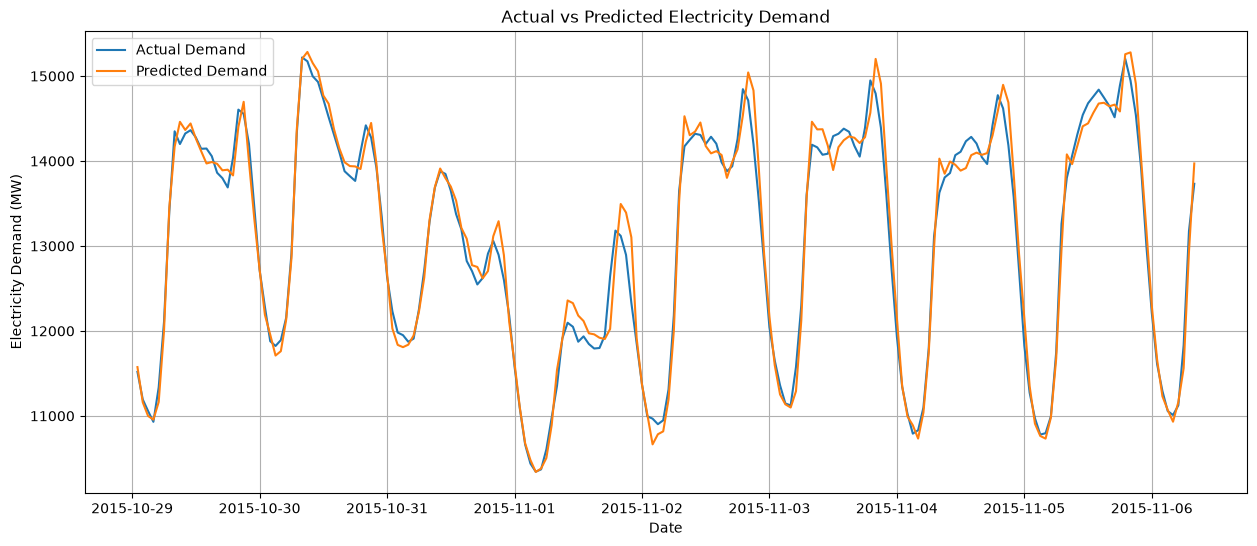

In [19]:
plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index[:200],
    y_test.values[:200],
    label="Actual Demand"
)

plt.plot(
    y_test.index[:200],
    y_pred[:200],
    label="Predicted Demand"
)

plt.title("Actual vs Predicted Electricity Demand")
plt.xlabel("Date")
plt.ylabel("Electricity Demand (MW)")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
def forecast_next_24_hours(model, history):

    history = history.copy()
    predictions = []

    for i in range(24):

        next_time = history.index[-1] + pd.Timedelta(hours=1)

        features = pd.DataFrame({
            "Hour": [next_time.hour],
            "Day": [next_time.day_of_week],
            "Month": [next_time.month],
            "Day_of_Year": [next_time.day_of_year],
            "Is_Weekend": [int(next_time.day_of_week >= 5)],
            "Lag_1": [history.iloc[-1]],
            "Lag_24": [history.iloc[-24]],
            "Lag_168": [history.iloc[-168]]
        })

        predicted_demand = model.predict(features)[0]

        predictions.append(predicted_demand)

        history.loc[next_time] = predicted_demand

    return predictions

In [22]:
# Find a test date with complete historical and future data
forecast_start = None

for candidate in X_test.index:

    previous_168 = pd.date_range(
        end=candidate - pd.Timedelta(hours=1),
        periods=168,
        freq="h"
    )

    next_24 = pd.date_range(
        start=candidate,
        periods=24,
        freq="h"
    )

    history_values = model_df["AEP_MW"].reindex(previous_168)
    actual_values = model_df["AEP_MW"].reindex(next_24)

    if history_values.notna().all() and actual_values.notna().all():
        forecast_start = candidate
        break

print("Forecast Start:", forecast_start)

Forecast Start: 2015-10-29 01:00:00


In [23]:
# Get the 168 hours before the forecast starts
history = model_df.loc[
    :forecast_start - pd.Timedelta(hours=1),
    "AEP_MW"
].tail(168)

# Generate 24-hour predictions
forecast_values = forecast_next_24_hours(
    rf_model,
    history
)

# Get actual demand for the same 24 hours
forecast_dates = pd.date_range(
    start=forecast_start,
    periods=24,
    freq="h"
)

actual_values = model_df.loc[
    forecast_dates,
    "AEP_MW"
]

# Create comparison table
forecast_comparison = pd.DataFrame({
    "Actual_Demand": actual_values.values,
    "Predicted_Demand": forecast_values
}, index=forecast_dates)

forecast_comparison.index.name = "Datetime"

forecast_comparison.head(24)

,Actual_Demand,Predicted_Demand
Datetime,,
2015-10-29 01:00:00,11518.0,11574.391324
2015-10-29 02:00:00,11193.0,11240.868865
2015-10-29 03:00:00,11057.0,11035.336117
2015-10-29 04:00:00,10930.0,10953.874941
2015-10-29 05:00:00,11336.0,11194.518364
2015-10-29 06:00:00,12106.0,11908.962006
2015-10-29 07:00:00,13407.0,13090.721010
2015-10-29 08:00:00,14350.0,14068.183850
2015-10-29 09:00:00,14200.0,14214.702435


In [24]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# Calculate 24-hour forecast metrics
forecast_mae = mean_absolute_error(
    forecast_comparison["Actual_Demand"],
    forecast_comparison["Predicted_Demand"]
)

forecast_rmse = np.sqrt(mean_squared_error(
    forecast_comparison["Actual_Demand"],
    forecast_comparison["Predicted_Demand"]
))

forecast_mape = mean_absolute_percentage_error(
    forecast_comparison["Actual_Demand"],
    forecast_comparison["Predicted_Demand"]
) * 100

forecast_r2 = r2_score(
    forecast_comparison["Actual_Demand"],
    forecast_comparison["Predicted_Demand"]
)

print("24-HOUR FORECAST PERFORMANCE")
print("----------------------------")
print("MAE:", round(forecast_mae, 2), "MW")
print("RMSE:", round(forecast_rmse, 2), "MW")
print("MAPE:", round(forecast_mape, 2), "%")
print("R2 Score:", round(forecast_r2, 4))

24-HOUR FORECAST PERFORMANCE
----------------------------
MAE: 125.22 MW
RMSE: 160.24 MW
MAPE: 0.93 %
R2 Score: 0.983


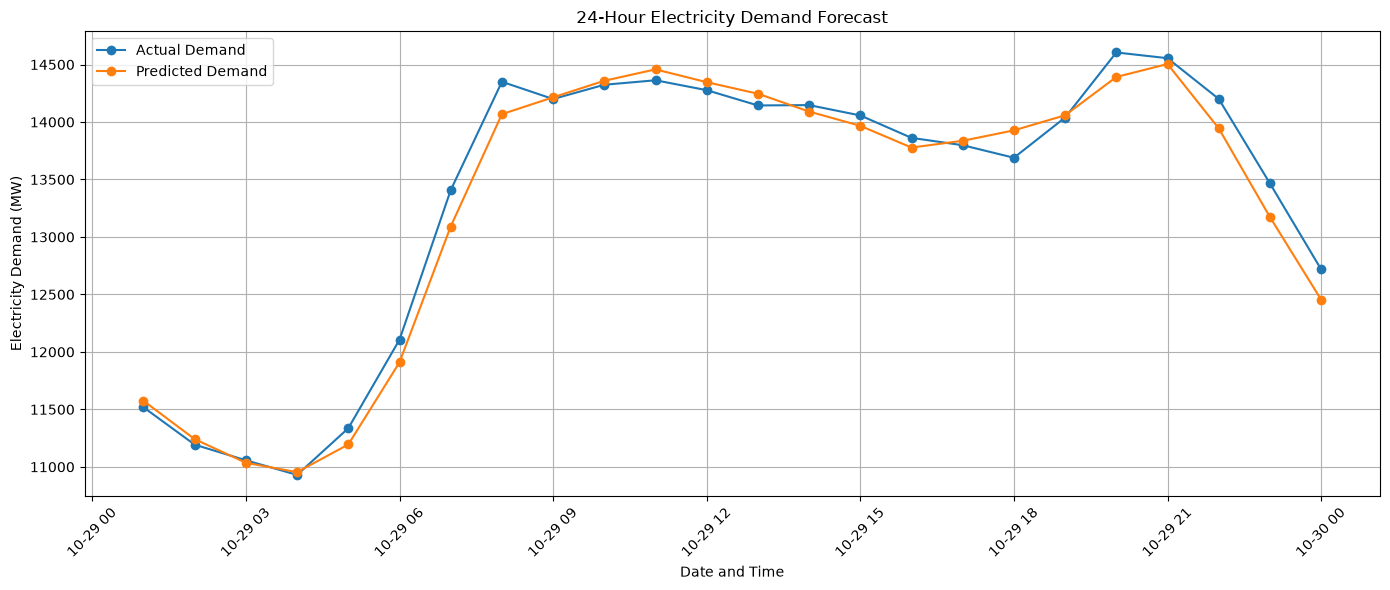

In [25]:
plt.figure(figsize=(14, 6))

plt.plot(
    forecast_comparison.index,
    forecast_comparison["Actual_Demand"],
    marker="o",
    label="Actual Demand"
)

plt.plot(
    forecast_comparison.index,
    forecast_comparison["Predicted_Demand"],
    marker="o",
    label="Predicted Demand"
)

plt.title("24-Hour Electricity Demand Forecast")
plt.xlabel("Date and Time")
plt.ylabel("Electricity Demand (MW)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [26]:
# Select 30 forecasting dates from the test dataset
test_dates = X_test.index

selected_dates = test_dates[
    np.linspace(0, len(test_dates) - 24, 30, dtype=int)
]

results = []

for start_time in selected_dates:

    # Get 168 hours of historical demand
    history_dates = pd.date_range(
        end=start_time - pd.Timedelta(hours=1),
        periods=168,
        freq="h"
    )

    # Get the next 24 hours of actual demand
    future_dates = pd.date_range(
        start=start_time,
        periods=24,
        freq="h"
    )

    history = model_df["AEP_MW"].reindex(history_dates)
    actual = model_df["AEP_MW"].reindex(future_dates)

    # Skip periods with missing values
    if history.isna().any() or actual.isna().any():
        continue

    # Generate 24-hour predictions
    predicted = forecast_next_24_hours(
        rf_model,
        history
    )

    # Store actual and predicted values
    for i in range(24):
        results.append({
            "Forecast_Start": start_time,
            "Datetime": future_dates[i],
            "Actual_Demand": actual.iloc[i],
            "Predicted_Demand": predicted[i]
        })

# Create results DataFrame
multi_day_results = pd.DataFrame(results)

print("Number of forecasting periods:",
      multi_day_results["Forecast_Start"].nunique())

print("Total predictions:",
      len(multi_day_results))

multi_day_results.head()

Number of forecasting periods: 28
Total predictions: 672


,Forecast_Start,Datetime,Actual_Demand,Predicted_Demand
0,2015-10-29 01:00:00,2015-10-29 01:00:00,11518.0,11574.391324
1,2015-10-29 01:00:00,2015-10-29 02:00:00,11193.0,11240.868865
2,2015-10-29 01:00:00,2015-10-29 03:00:00,11057.0,11035.336117
3,2015-10-29 01:00:00,2015-10-29 04:00:00,10930.0,10953.874941
4,2015-10-29 01:00:00,2015-10-29 05:00:00,11336.0,11194.518364


In [27]:
# Extract actual and predicted values
actual_multi = multi_day_results["Actual_Demand"]
predicted_multi = multi_day_results["Predicted_Demand"]

# Calculate evaluation metrics
multi_mae = mean_absolute_error(
    actual_multi, predicted_multi
)

multi_rmse = np.sqrt(mean_squared_error(
    actual_multi, predicted_multi
))

multi_mape = mean_absolute_percentage_error(
    actual_multi, predicted_multi
) * 100

multi_r2 = r2_score(
    actual_multi, predicted_multi
)

# Display results
print("MULTIPLE 24-HOUR FORECAST PERFORMANCE")
print("-------------------------------------")
print("Forecasting Periods:",
      multi_day_results["Forecast_Start"].nunique())
print("Total Predictions:", len(multi_day_results))
print("MAE:", round(multi_mae, 2), "MW")
print("RMSE:", round(multi_rmse, 2), "MW")
print("MAPE:", round(multi_mape, 2), "%")
print("R2 Score:", round(multi_r2, 4))

MULTIPLE 24-HOUR FORECAST PERFORMANCE
-------------------------------------
Forecasting Periods: 28
Total Predictions: 672
MAE: 732.69 MW
RMSE: 1029.19 MW
MAPE: 4.74 %
R2 Score: 0.8646


In [28]:
# Identify the forecast hour (1 to 24)
multi_day_results["Forecast_Hour"] = (
    multi_day_results.groupby("Forecast_Start").cumcount() + 1
)

# Calculate MAE for each forecast hour
hourly_performance = (
    multi_day_results.groupby("Forecast_Hour")
    .apply(
        lambda group: mean_absolute_error(
            group["Actual_Demand"],
            group["Predicted_Demand"]
        ),
        include_groups=False
    )
    .reset_index(name="MAE_MW")
)

print(hourly_performance)

    Forecast_Hour       MAE_MW
0               1   180.446612
1               2   311.115422
2               3   444.073246
3               4   499.495070
4               5   524.917355
5               6   530.193432
6               7   579.993113
7               8   608.304421
8               9   679.792073
9              10   697.214790
10             11   788.004277
11             12   885.811316
12             13   964.140851
13             14  1000.716961
14             15  1033.978793
15             16   997.747931
16             17   954.760044
17             18   918.979612
18             19   876.064992
19             20   850.820505
20             21   782.034402
21             22   790.656508
22             23   804.191439
23             24   881.093979


In [29]:
# Get feature importance from Random Forest
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

       Feature  Importance
5        Lag_1    0.955148
0         Hour    0.035527
3  Day_of_Year    0.005336
6       Lag_24    0.001086
1          Day    0.000896
2        Month    0.000828
7      Lag_168    0.000608
4   Is_Weekend    0.000571


In [30]:
# Create an improved copy of the modelling dataset
improved_df = model_df.copy()

# Rolling features use only past observations
improved_df["Rolling_Mean_3"] = (
    improved_df["AEP_MW"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

improved_df["Rolling_Mean_24"] = (
    improved_df["AEP_MW"]
    .shift(1)
    .rolling(window=24)
    .mean()
)

improved_df["Rolling_Std_24"] = (
    improved_df["AEP_MW"]
    .shift(1)
    .rolling(window=24)
    .std()
)

print("New rolling features created successfully!")

print(improved_df[
    ["AEP_MW", "Rolling_Mean_3",
     "Rolling_Mean_24", "Rolling_Std_24"]
].tail())

New rolling features created successfully!
                      AEP_MW  Rolling_Mean_3  Rolling_Mean_24  Rolling_Std_24
Datetime                                                                     
2018-08-02 20:00:00  17673.0    18516.333333     15543.958333     2313.121991
2018-08-02 21:00:00  17303.0    18117.666667     15589.541667     2344.965986
2018-08-02 22:00:00  17001.0    17698.000000     15624.791667     2364.847085
2018-08-02 23:00:00  15964.0    17325.666667     15658.291667     2378.957873
2018-08-03 00:00:00  14809.0    16756.000000     15687.666667     2378.165600


In [31]:
# Select all features for the improved model
improved_features = [
    "Hour",
    "Day",
    "Month",
    "Day_of_Year",
    "Is_Weekend",
    "Lag_1",
    "Lag_24",
    "Lag_168",
    "Rolling_Mean_3",
    "Rolling_Mean_24",
    "Rolling_Std_24"
]

# Create the final improved dataset
improved_final_df = improved_df[
    ["AEP_MW"] + improved_features
].dropna().copy()

# Separate input features and target
X_improved = improved_final_df[improved_features]
y_improved = improved_final_df["AEP_MW"]

# Chronological 80:20 split
split_index_2 = int(len(X_improved) * 0.80)

X_train_improved = X_improved.iloc[:split_index_2]
X_test_improved = X_improved.iloc[split_index_2:]

y_train_improved = y_improved.iloc[:split_index_2]
y_test_improved = y_improved.iloc[split_index_2:]

# Display dataset information
print("Improved Dataset Shape:", improved_final_df.shape)
print("Number of Features:", len(improved_features))
print("Training Data:", X_train_improved.shape)
print("Testing Data:", X_test_improved.shape)
print("Missing Values:", improved_final_df.isnull().sum().sum())

Improved Dataset Shape: (120426, 12)
Number of Features: 11
Training Data: (96340, 11)
Testing Data: (24086, 11)
Missing Values: 0


In [32]:
from sklearn.ensemble import RandomForestRegressor

# Create improved Random Forest model
improved_rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

print("Training Improved Random Forest Model...")

improved_rf_model.fit(
    X_train_improved,
    y_train_improved
)

print("Improved Model Training Completed Successfully!")

Training Improved Random Forest Model...
Improved Model Training Completed Successfully!


In [33]:
# Generate predictions on improved test data
y_pred_improved = improved_rf_model.predict(X_test_improved)

print("Improved model predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test_improved.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_improved[:10])

Improved model predictions generated successfully!

First 10 Actual Values:
[11909. 12253. 12715. 13283. 13686. 13880. 13848. 13651. 13375. 13194.]

First 10 Predicted Values:
[11968.42266071 12124.46127265 12687.63898106 13248.01989777
 13720.44222456 13839.3744241  13850.68838342 13828.48905078
 13509.37213698 13170.41002017]


In [34]:
# Calculate evaluation metrics
improved_mae = mean_absolute_error(
    y_test_improved, y_pred_improved
)

improved_rmse = np.sqrt(mean_squared_error(
    y_test_improved, y_pred_improved
))

improved_mape = mean_absolute_percentage_error(
    y_test_improved, y_pred_improved
) * 100

improved_r2 = r2_score(
    y_test_improved, y_pred_improved
)

print("IMPROVED RANDOM FOREST PERFORMANCE")
print("----------------------------------")
print("MAE:", round(improved_mae, 2), "MW")
print("RMSE:", round(improved_rmse, 2), "MW")
print("MAPE:", round(improved_mape, 2), "%")
print("R2 Score:", round(improved_r2, 4))

IMPROVED RANDOM FOREST PERFORMANCE
----------------------------------
MAE: 136.34 MW
RMSE: 188.6 MW
MAPE: 0.93 %
R2 Score: 0.9941


In [35]:
# Find common test timestamps
common_dates = X_test.index.intersection(
    X_test_improved.index
)

# Select identical test data for both models
X_original_common = X_test.loc[common_dates]
X_improved_common = X_test_improved.loc[common_dates]

y_common = y_test.loc[common_dates]

# Generate predictions
original_common_pred = rf_model.predict(
    X_original_common
)

improved_common_pred = improved_rf_model.predict(
    X_improved_common
)

# Calculate metrics for original model
original_common_mae = mean_absolute_error(
    y_common, original_common_pred
)

original_common_rmse = np.sqrt(mean_squared_error(
    y_common, original_common_pred
))

original_common_mape = mean_absolute_percentage_error(
    y_common, original_common_pred
) * 100

original_common_r2 = r2_score(
    y_common, original_common_pred
)

# Calculate metrics for improved model
improved_common_mae = mean_absolute_error(
    y_common, improved_common_pred
)

improved_common_rmse = np.sqrt(mean_squared_error(
    y_common, improved_common_pred
))

improved_common_mape = mean_absolute_percentage_error(
    y_common, improved_common_pred
) * 100

improved_common_r2 = r2_score(
    y_common, improved_common_pred
)

# Display fair comparison
comparison = pd.DataFrame({
    "Metric": ["MAE (MW)", "RMSE (MW)", "MAPE (%)", "R2 Score"],
    "Original RF": [
        original_common_mae,
        original_common_rmse,
        original_common_mape,
        original_common_r2
    ],
    "Improved RF": [
        improved_common_mae,
        improved_common_rmse,
        improved_common_mape,
        improved_common_r2
    ]
})

print("COMMON TEST RECORDS:", len(common_dates))
print(comparison.round(4))

COMMON TEST RECORDS: 24086
      Metric  Original RF  Improved RF
0   MAE (MW)     154.1616     136.3390
1  RMSE (MW)     206.5874     188.5966
2   MAPE (%)       1.0508       0.9331
3   R2 Score       0.9929       0.9941


In [36]:
improved_feature_importance = pd.DataFrame({
    "Feature": X_train_improved.columns,
    "Importance": improved_rf_model.feature_importances_
})

improved_feature_importance = (
    improved_feature_importance
    .sort_values(
        by="Importance",
        ascending=False
    )
)

print(improved_feature_importance)

            Feature  Importance
5             Lag_1    0.956126
0              Hour    0.026394
8    Rolling_Mean_3    0.009106
9   Rolling_Mean_24    0.003201
10   Rolling_Std_24    0.002469
3       Day_of_Year    0.000687
1               Day    0.000644
6            Lag_24    0.000511
4        Is_Weekend    0.000415
7           Lag_168    0.000327
2             Month    0.000123


In [38]:
def improved_forecast_24_hours(model, history):

    history = history.copy()
    predictions = []

    for i in range(24):

        next_time = history.index[-1] + pd.Timedelta(hours=1)

        features = pd.DataFrame({
            "Hour": [next_time.hour],
            "Day": [next_time.day_of_week],
            "Month": [next_time.month],
            "Day_of_Year": [next_time.day_of_year],
            "Is_Weekend": [int(next_time.day_of_week >= 5)],

            "Lag_1": [history.iloc[-1]],
            "Lag_24": [history.iloc[-24]],
            "Lag_168": [history.iloc[-168]],

            "Rolling_Mean_3": [history.iloc[-3:].mean()],
            "Rolling_Mean_24": [history.iloc[-24:].mean()],
            "Rolling_Std_24": [history.iloc[-24:].std()]
        })

        predicted_demand = model.predict(features)[0]

        predictions.append(predicted_demand)

        history.loc[next_time] = predicted_demand

    return predictions

In [39]:
improved_results = []

for start_time in selected_dates:

    # Get previous 168 hours
    history_dates = pd.date_range(
        end=start_time - pd.Timedelta(hours=1),
        periods=168,
        freq="h"
    )

    # Get next 24 hours
    future_dates = pd.date_range(
        start=start_time,
        periods=24,
        freq="h"
    )

    history = improved_df["AEP_MW"].reindex(history_dates)
    actual = improved_df["AEP_MW"].reindex(future_dates)

    # Skip periods with missing values
    if history.isna().any() or actual.isna().any():
        continue

    # Generate improved model predictions
    predicted = improved_forecast_24_hours(
        improved_rf_model,
        history
    )

    # Store results
    for i in range(24):
        improved_results.append({
            "Forecast_Start": start_time,
            "Datetime": future_dates[i],
            "Actual_Demand": actual.iloc[i],
            "Predicted_Demand": predicted[i]
        })

# Create results DataFrame
improved_multi_results = pd.DataFrame(improved_results)

print(
    "Forecasting Periods:",
    improved_multi_results["Forecast_Start"].nunique()
)

print("Total Predictions:", len(improved_multi_results))

improved_multi_results.head()

Forecasting Periods: 28
Total Predictions: 672


,Forecast_Start,Datetime,Actual_Demand,Predicted_Demand
0,2015-10-29 01:00:00,2015-10-29 01:00:00,11518.0,11547.046778
1,2015-10-29 01:00:00,2015-10-29 02:00:00,11193.0,11170.488019
2,2015-10-29 01:00:00,2015-10-29 03:00:00,11057.0,11014.749662
3,2015-10-29 01:00:00,2015-10-29 04:00:00,10930.0,10971.109230
4,2015-10-29 01:00:00,2015-10-29 05:00:00,11336.0,11269.580003


In [40]:
# Extract actual and predicted values
actual_improved = improved_multi_results["Actual_Demand"]
predicted_improved = improved_multi_results["Predicted_Demand"]

# Calculate evaluation metrics
improved_24h_mae = mean_absolute_error(
    actual_improved, predicted_improved
)

improved_24h_rmse = np.sqrt(mean_squared_error(
    actual_improved, predicted_improved
))

improved_24h_mape = mean_absolute_percentage_error(
    actual_improved, predicted_improved
) * 100

improved_24h_r2 = r2_score(
    actual_improved, predicted_improved
)

print("IMPROVED MODEL - 24 HOUR FORECAST")
print("---------------------------------")
print("Forecasting Periods:",
      improved_multi_results["Forecast_Start"].nunique())
print("Total Predictions:", len(improved_multi_results))
print("MAE:", round(improved_24h_mae, 2), "MW")
print("RMSE:", round(improved_24h_rmse, 2), "MW")
print("MAPE:", round(improved_24h_mape, 2), "%")
print("R2 Score:", round(improved_24h_r2, 4))

IMPROVED MODEL - 24 HOUR FORECAST
---------------------------------
Forecasting Periods: 28
Total Predictions: 672
MAE: 723.28 MW
RMSE: 1009.95 MW
MAPE: 4.67 %
R2 Score: 0.8696


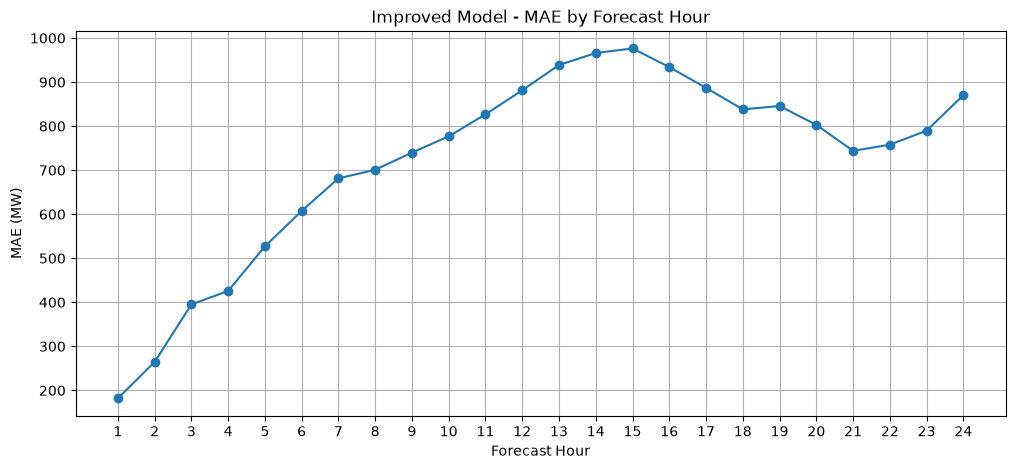

In [41]:
improved_multi_results["Forecast_Hour"] = (
    improved_multi_results.groupby("Forecast_Start").cumcount() + 1
)

hourly_improved_mae = (
    improved_multi_results.groupby("Forecast_Hour")
    .apply(
        lambda group: mean_absolute_error(
            group["Actual_Demand"],
            group["Predicted_Demand"]
        ),
        include_groups=False
    )
)

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_improved_mae.index,
    hourly_improved_mae.values,
    marker="o"
)

plt.title("Improved Model - MAE by Forecast Hour")
plt.xlabel("Forecast Hour")
plt.ylabel("MAE (MW)")
plt.xticks(range(1, 25))
plt.grid(True)
plt.show()

In [42]:
# Calculate original model's MAE for each forecast hour
original_multi_results["Forecast_Hour"] = (
    original_multi_results.groupby("Forecast_Start").cumcount() + 1
)

original_hourly_mae = (
    original_multi_results.groupby("Forecast_Hour")
    .apply(
        lambda group: mean_absolute_error(
            group["Actual_Demand"],
            group["Predicted_Demand"]
        ),
        include_groups=False
    )
)

# Compare both models
hourly_comparison = pd.DataFrame({
    "Original_RF_MAE": original_hourly_mae,
    "Improved_RF_MAE": hourly_improved_mae
})

hourly_comparison["Improvement_MW"] = (
    hourly_comparison["Original_RF_MAE"]
    - hourly_comparison["Improved_RF_MAE"]
)

display(hourly_comparison.round(2))

NameError: name 'original_multi_results' is not defined

In [43]:
%whos

Variable                         Type                     Data/Info
-------------------------------------------------------------------
RandomForestRegressor            ABCMeta                  <class 'sklearn.ensemble.<...>t.RandomForestRegressor'>
X                                DataFrame                Shape: (121020, 8)
X_improved                       DataFrame                Shape: (120426, 11)
X_improved_common                DataFrame                Shape: (24086, 11)
X_original_common                DataFrame                Shape: (24086, 8)
X_test                           DataFrame                Shape: (24204, 8)
X_test_improved                  DataFrame                Shape: (24086, 11)
X_train                          DataFrame                Shape: (96816, 8)
X_train_improved                 DataFrame                Shape: (96340, 11)
actual                           Series                   Shape: (24,)
actual_improved                  Series                   Shape: 

In [44]:
%whos

Variable                         Type                     Data/Info
-------------------------------------------------------------------
RandomForestRegressor            ABCMeta                  <class 'sklearn.ensemble.<...>t.RandomForestRegressor'>
X                                DataFrame                Shape: (121020, 8)
X_improved                       DataFrame                Shape: (120426, 11)
X_improved_common                DataFrame                Shape: (24086, 11)
X_original_common                DataFrame                Shape: (24086, 8)
X_test                           DataFrame                Shape: (24204, 8)
X_test_improved                  DataFrame                Shape: (24086, 11)
X_train                          DataFrame                Shape: (96816, 8)
X_train_improved                 DataFrame                Shape: (96340, 11)
actual                           Series                   Shape: (24,)
actual_improved                  Series                   Shape: 

In [45]:
for name in globals():
    if any(word in name.lower() for word in ["multi", "pred", "result", "hourly"]):
        obj = globals()[name]
        print(name, type(obj).__name__, getattr(obj, "shape", ""))
        

RuntimeError: dictionary changed size during iteration

In [46]:
for name, obj in list(globals().items()):
    if any(word in name.lower() for word in ["multi", "pred", "result", "hourly"]):
        print(name, type(obj).__name__, getattr(obj, "shape", ""))

y_pred ndarray (24204,)
results list 
predicted list 
multi_day_results DataFrame (672, 5)
actual_multi Series (672,)
predicted_multi Series (672,)
multi_mae float 
multi_rmse float64 ()
multi_mape float 
multi_r2 float 
hourly_performance DataFrame (24, 2)
y_pred_improved ndarray (24086,)
original_common_pred ndarray (24086,)
improved_common_pred ndarray (24086,)
improved_results list 
improved_multi_results DataFrame (672, 5)
predicted_improved Series (672,)
hourly_improved_mae Series (24,)


In [47]:
# Add forecast hour to original results
multi_day_results["Forecast_Hour"] = (
    multi_day_results.groupby("Forecast_Start").cumcount() + 1
)

# Calculate original model's hourly MAE
original_hourly_mae = (
    multi_day_results.groupby("Forecast_Hour")
    .apply(
        lambda group: mean_absolute_error(
            group["Actual_Demand"],
            group["Predicted_Demand"]
        ),
        include_groups=False
    )
)

# Compare original and improved models
hourly_comparison = pd.DataFrame({
    "Original_RF_MAE": original_hourly_mae,
    "Improved_RF_MAE": hourly_improved_mae
})

hourly_comparison["Improvement_MW"] = (
    hourly_comparison["Original_RF_MAE"]
    - hourly_comparison["Improved_RF_MAE"]
)

display(hourly_comparison.round(2))

,Original_RF_MAE,Improved_RF_MAE,Improvement_MW
Forecast_Hour,,,
1,180.45,181.65,-1.20
2,311.12,264.64,46.48
3,444.07,395.10,48.97
4,499.50,425.78,73.71
5,524.92,526.97,-2.05
6,530.19,607.42,-77.23
7,579.99,681.37,-101.38
8,608.30,700.81,-92.50
9,679.79,739.88,-60.09


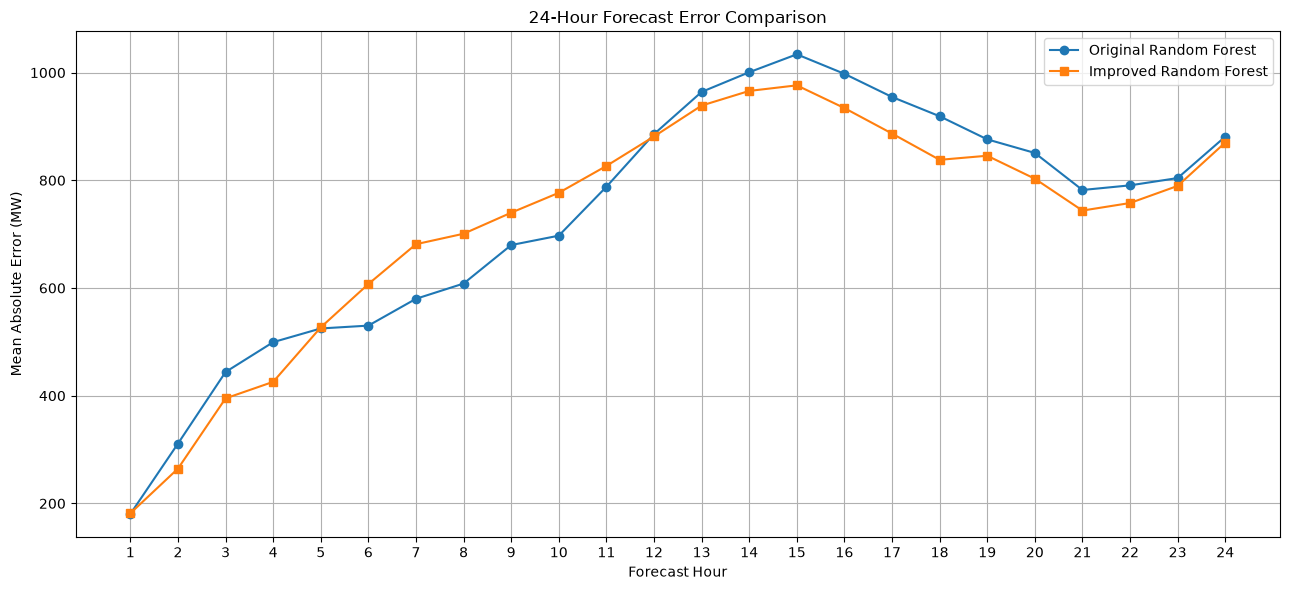

In [48]:
plt.figure(figsize=(13, 6))

plt.plot(
    hourly_comparison.index,
    hourly_comparison["Original_RF_MAE"],
    marker="o",
    label="Original Random Forest"
)

plt.plot(
    hourly_comparison.index,
    hourly_comparison["Improved_RF_MAE"],
    marker="s",
    label="Improved Random Forest"
)

plt.title("24-Hour Forecast Error Comparison")
plt.xlabel("Forecast Hour")
plt.ylabel("Mean Absolute Error (MW)")
plt.xticks(range(1, 25))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [49]:
# Calculate residuals for the improved model
improved_multi_results["Residual"] = (
    improved_multi_results["Actual_Demand"]
    - improved_multi_results["Predicted_Demand"]
)

# Display summary
print("RESIDUAL ANALYSIS")
print("-----------------")
print("Mean Residual:", improved_multi_results["Residual"].mean())
print("Minimum Residual:", improved_multi_results["Residual"].min())
print("Maximum Residual:", improved_multi_results["Residual"].max())
print("Standard Deviation:", improved_multi_results["Residual"].std())

RESIDUAL ANALYSIS
-----------------
Mean Residual: 62.74362170334052
Minimum Residual: -2808.174947001651
Maximum Residual: 3952.139721813557
Standard Deviation: 1008.7487572246775


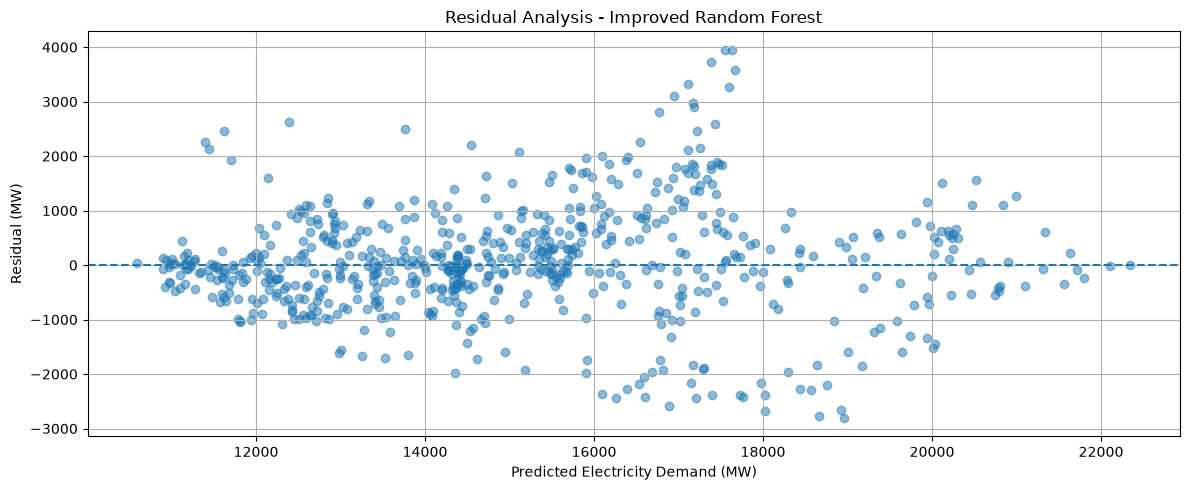

In [50]:
plt.figure(figsize=(12, 5))

plt.scatter(
    improved_multi_results["Predicted_Demand"],
    improved_multi_results["Residual"],
    alpha=0.5
)

plt.axhline(y=0, linestyle="--")

plt.title("Residual Analysis - Improved Random Forest")
plt.xlabel("Predicted Electricity Demand (MW)")
plt.ylabel("Residual (MW)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [51]:
# Calculate demand thresholds
low_threshold = improved_multi_results["Actual_Demand"].quantile(0.33)
high_threshold = improved_multi_results["Actual_Demand"].quantile(0.66)

# Classify demand levels
improved_multi_results["Demand_Level"] = pd.cut(
    improved_multi_results["Actual_Demand"],
    bins=[
        -np.inf,
        low_threshold,
        high_threshold,
        np.inf
    ],
    labels=["Low", "Medium", "High"]
)

# Calculate performance for each demand level
demand_performance = (
    improved_multi_results.groupby("Demand_Level", observed=True)
    .apply(
        lambda group: pd.Series({
            "Average_Actual_Demand": group["Actual_Demand"].mean(),
            "Average_Predicted_Demand": group["Predicted_Demand"].mean(),
            "MAE": mean_absolute_error(
                group["Actual_Demand"],
                group["Predicted_Demand"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                group["Actual_Demand"],
                group["Predicted_Demand"]
            )),
            "Number_of_Predictions": len(group)
        }),
        include_groups=False
    )
)

display(demand_performance.round(2))

,Average_Actual_Demand,Average_Predicted_Demand,MAE,RMSE,Number_of_Predictions
Demand_Level,,,,,
Low,12201.28,12498.18,512.42,676.16,222.0
Medium,14777.41,14901.69,634.79,938.31,221.0
High,18375.39,17783.50,1013.11,1303.95,229.0


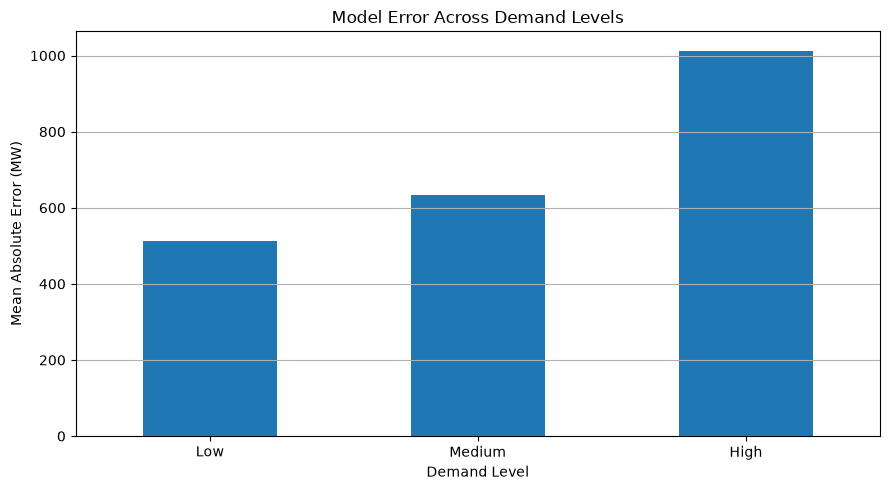

In [52]:
plt.figure(figsize=(9, 5))

demand_performance["MAE"].plot(
    kind="bar",
    rot=0
)

plt.title("Model Error Across Demand Levels")
plt.xlabel("Demand Level")
plt.ylabel("Mean Absolute Error (MW)")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [53]:
# Positive residual = underprediction
# Negative residual = overprediction

improved_multi_results["Error_Type"] = np.where(
    improved_multi_results["Residual"] > 0,
    "Underprediction",
    "Overprediction"
)

error_analysis = pd.crosstab(
    improved_multi_results["Demand_Level"],
    improved_multi_results["Error_Type"]
)

display(error_analysis)

Error_Type,Overprediction,Underprediction
Demand_Level,,
Low,157,65
Medium,115,106
High,67,162


In [54]:
bias_analysis = (
    improved_multi_results.groupby("Demand_Level", observed=True)
    .agg(
        Average_Residual=("Residual", "mean"),
        Maximum_Underprediction=("Residual", "max"),
        Maximum_Overprediction=("Residual", "min")
    )
)

display(bias_analysis.round(2))

,Average_Residual,Maximum_Underprediction,Maximum_Overprediction
Demand_Level,,,
Low,-296.90,2139.17,-1980.13
Medium,-124.29,2628.92,-2765.50
High,591.89,3952.14,-2808.17


In [55]:
from sklearn.ensemble import RandomForestRegressor

# Give higher importance to high-demand training observations
demand_weights = np.where(
    y_train_improved >= y_train_improved.quantile(0.80),
    2.0,
    1.0
)

# Train peak-focused model
peak_rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

peak_rf_model.fit(
    X_train_improved,
    y_train_improved,
    sample_weight=demand_weights
)

print("Peak-focused Random Forest model trained successfully!")

Peak-focused Random Forest model trained successfully!


In [56]:
# Store peak-focused forecast results
peak_multi_results = []

for start_time in selected_dates:

    history = improved_df.loc[
        improved_df.index < start_time, "AEP_MW"
    ].tail(168)

    actual_values = improved_df.loc[
        start_time:start_time + pd.Timedelta(hours=23),
        "AEP_MW"
    ]

    if len(history) < 168 or history.isna().any() or actual_values.isna().any():
        continue

    predictions = improved_forecast_24_hours(
        peak_rf_model,
        history
    )

    for i in range(24):
        forecast_time = start_time + pd.Timedelta(hours=i)

        peak_multi_results.append({
            "Forecast_Start": start_time,
            "Datetime": forecast_time,
            "Actual_Demand": actual_values.iloc[i],
            "Predicted_Demand": predictions[i]
        })

peak_multi_results = pd.DataFrame(peak_multi_results)

print("Peak-focused forecasting periods:",
      peak_multi_results["Forecast_Start"].nunique())

print("Total predictions:",
      len(peak_multi_results))

display(peak_multi_results.head())

Peak-focused forecasting periods: 28
Total predictions: 672


,Forecast_Start,Datetime,Actual_Demand,Predicted_Demand
0,2015-10-29 01:00:00,2015-10-29 01:00:00,11518.0,11529.659607
1,2015-10-29 01:00:00,2015-10-29 02:00:00,11193.0,11154.236089
2,2015-10-29 01:00:00,2015-10-29 03:00:00,11057.0,10997.315402
3,2015-10-29 01:00:00,2015-10-29 04:00:00,10930.0,10954.529997
4,2015-10-29 01:00:00,2015-10-29 05:00:00,11336.0,11240.389402


In [57]:
peak_actual = peak_multi_results["Actual_Demand"]
peak_predicted = peak_multi_results["Predicted_Demand"]

peak_mae = mean_absolute_error(peak_actual, peak_predicted)

peak_rmse = np.sqrt(
    mean_squared_error(peak_actual, peak_predicted)
)

peak_mape = mean_absolute_percentage_error(
    peak_actual, peak_predicted
) * 100

peak_r2 = r2_score(peak_actual, peak_predicted)

print("PEAK-FOCUSED RANDOM FOREST - 24 HOUR FORECAST")
print("---------------------------------------------")
print("MAE:", round(peak_mae, 2), "MW")
print("RMSE:", round(peak_rmse, 2), "MW")
print("MAPE:", round(peak_mape, 2), "%")
print("R2 Score:", round(peak_r2, 4))

PEAK-FOCUSED RANDOM FOREST - 24 HOUR FORECAST
---------------------------------------------
MAE: 749.6 MW
RMSE: 1061.45 MW
MAPE: 4.78 %
R2 Score: 0.856


In [58]:
# Use the same high-demand threshold for all models
high_threshold = improved_multi_results["Actual_Demand"].quantile(0.66)

# Select high-demand observations
original_high = multi_day_results[
    multi_day_results["Actual_Demand"] >= high_threshold
]

improved_high = improved_multi_results[
    improved_multi_results["Actual_Demand"] >= high_threshold
]

peak_high = peak_multi_results[
    peak_multi_results["Actual_Demand"] >= high_threshold
]

# Calculate high-demand MAE
high_demand_comparison = pd.DataFrame({
    "Model": [
        "Original RF",
        "Improved RF",
        "Peak-focused RF"
    ],
    "High_Demand_MAE": [
        mean_absolute_error(
            original_high["Actual_Demand"],
            original_high["Predicted_Demand"]
        ),
        mean_absolute_error(
            improved_high["Actual_Demand"],
            improved_high["Predicted_Demand"]
        ),
        mean_absolute_error(
            peak_high["Actual_Demand"],
            peak_high["Predicted_Demand"]
        )
    ]
})

display(high_demand_comparison.round(2))

,Model,High_Demand_MAE
0,Original RF,1012.07
1,Improved RF,1013.11
2,Peak-focused RF,1075.26


In [59]:
def calculate_demand_metrics(data):
    results = []

    for level in ["Low", "Medium", "High"]:
        actual = data.loc[
            data["Demand_Level"] == level, "Actual_Demand"
        ]
        predicted = data.loc[
            data["Demand_Level"] == level, "Predicted_Demand"
        ]

        results.append({
            "Demand_Level": level,
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted))
        })

    return pd.DataFrame(results)


# Use the same thresholds for all three models
for data in [
    multi_day_results,
    improved_multi_results,
    peak_multi_results
]:
    data["Demand_Level"] = pd.cut(
        data["Actual_Demand"],
        bins=[-np.inf, low_threshold, high_threshold, np.inf],
        labels=["Low", "Medium", "High"]
    )

original_demand_metrics = calculate_demand_metrics(multi_day_results)
improved_demand_metrics = calculate_demand_metrics(improved_multi_results)
peak_demand_metrics = calculate_demand_metrics(peak_multi_results)

print("ORIGINAL RANDOM FOREST")
display(original_demand_metrics.round(2))

print("IMPROVED RANDOM FOREST")
display(improved_demand_metrics.round(2))

print("PEAK-FOCUSED RANDOM FOREST")
display(peak_demand_metrics.round(2))

ORIGINAL RANDOM FOREST


,Demand_Level,MAE,RMSE
0,Low,502.11,625.69
1,Medium,674.82,998.86
2,High,1012.07,1328.87


IMPROVED RANDOM FOREST


,Demand_Level,MAE,RMSE
0,Low,512.42,676.16
1,Medium,634.79,938.31
2,High,1013.11,1303.95


PEAK-FOCUSED RANDOM FOREST


,Demand_Level,MAE,RMSE
0,Low,503.84,665.66
1,Medium,659.02,949.76
2,High,1075.26,1416.38


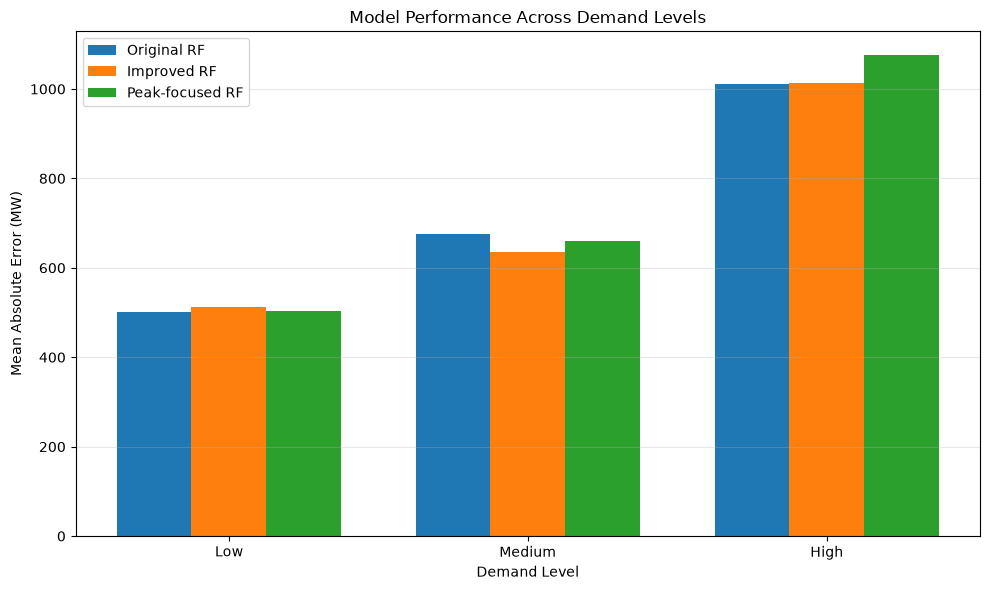

In [60]:
demand_levels = ["Low", "Medium", "High"]

original_mae = original_demand_metrics["MAE"].values
improved_mae = improved_demand_metrics["MAE"].values
peak_mae = peak_demand_metrics["MAE"].values

x = np.arange(len(demand_levels))
width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(x - width, original_mae, width, label="Original RF")
plt.bar(x, improved_mae, width, label="Improved RF")
plt.bar(x + width, peak_mae, width, label="Peak-focused RF")

plt.title("Model Performance Across Demand Levels")
plt.xlabel("Demand Level")
plt.ylabel("Mean Absolute Error (MW)")
plt.xticks(x, demand_levels)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [61]:
print("FINAL MODEL CHECK")
print("-----------------")

print("Model:", type(improved_rf_model).__name__)

print("Training records:", len(X_train_improved))

print("Number of features:", len(improved_features))

print("\nFeatures used by the model:")
for feature in improved_features:
    print("-", feature)

print("\nModel training completed:",
      hasattr(improved_rf_model, "estimators_"))

FINAL MODEL CHECK
-----------------
Model: RandomForestRegressor
Training records: 96340
Number of features: 11

Features used by the model:
- Hour
- Day
- Month
- Day_of_Year
- Is_Weekend
- Lag_1
- Lag_24
- Lag_168
- Rolling_Mean_3
- Rolling_Mean_24
- Rolling_Std_24

Model training completed: True


In [62]:
import joblib
import os

model_artifacts = {
    "model": improved_rf_model,
    "features": improved_features,
    "model_name": "Improved Random Forest",
    "target": "AEP_MW",
    "unit": "MW",
    "forecast_horizon": 24
}

joblib.dump(
    model_artifacts,
    "improved_electricity_model.joblib"
)

print("Improved model saved successfully!")
print("File location:")
print(os.path.abspath("improved_electricity_model.joblib"))

Improved model saved successfully!
File location:
c:\Users\sarit\OneDrive\Documents\Electricity_Demand_Forecasting\improved_electricity_model.joblib


In [63]:
evaluation_results = {
    "Original Random Forest": {
        "MAE": multi_mae,
        "RMSE": multi_rmse,
        "MAPE": multi_mape,
        "R2": multi_r2
    },
    "Improved Random Forest": {
        "MAE": improved_24h_mae,
        "RMSE": improved_24h_rmse,
        "MAPE": improved_24h_mape,
        "R2": improved_24h_r2
    },
    "Peak-focused Random Forest": {
        "MAE": peak_mae,
        "RMSE": peak_rmse,
        "MAPE": peak_mape,
        "R2": peak_r2
    }
}

joblib.dump(
    evaluation_results,
    "model_evaluation_results.joblib"
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [64]:
saved_model_artifacts = joblib.load("improved_electricity_model.joblib")
saved_evaluation_results = joblib.load("model_evaluation_results.joblib")

print("Model:", type(saved_model_artifacts["model"]).__name__)
print("Number of features:", len(saved_model_artifacts["features"]))
print("\nSaved evaluation results:")
print(saved_evaluation_results)

Model: RandomForestRegressor
Number of features: 11

Saved evaluation results:
{'Original Random Forest': {'MAE': 732.689464376132, 'RMSE': np.float64(1029.1851925525796), 'MAPE': 4.73660281233771, 'R2': 0.8646016164808557}, 'Improved Random Forest': {'MAE': 723.2848926193944, 'RMSE': np.float64(1009.9487958113656), 'MAPE': 4.673378337471721, 'R2': 0.8696157501835168}, 'Peak-focused Random Forest': {'MAE': array([ 503.84417697,  659.01755752, 1075.26123688]), 'RMSE': np.float64(1061.4490568856952), 'MAPE': 4.782253085739964, 'R2': 0.8559793614400117}}


In [65]:
evaluation_results["Peak-focused Random Forest"]["MAE"] = peak_mae

joblib.dump(
    evaluation_results,
    "model_evaluation_results.joblib"
)

print("Evaluation results corrected and saved!")
print(evaluation_results["Peak-focused Random Forest"])

Evaluation results corrected and saved!
{'MAE': array([ 503.84417697,  659.01755752, 1075.26123688]), 'RMSE': np.float64(1061.4490568856952), 'MAPE': 4.782253085739964, 'R2': 0.8559793614400117}


In [67]:
from sklearn.metrics import mean_absolute_error

overall_peak_mae = mean_absolute_error(
    peak_multi_results["Actual_Demand"],
    peak_multi_results["Predicted_Demand"]
)

print("Overall Peak-focused MAE:", round(overall_peak_mae, 2))

Overall Peak-focused MAE: 749.6


In [68]:
evaluation_results["Peak-focused Random Forest"]["MAE"] = overall_peak_mae

joblib.dump(
    evaluation_results,
    "model_evaluation_results.joblib"
)

print("Corrected evaluation results saved successfully!")

print(
    "Peak-focused overall MAE:",
    evaluation_results["Peak-focused Random Forest"]["MAE"]
)

Corrected evaluation results saved successfully!
Peak-focused overall MAE: 749.5998671817686


In [69]:
import joblib
import pandas as pd
import numpy as np

saved_model_artifacts = joblib.load("improved_electricity_model.joblib")

forecast_model = saved_model_artifacts["model"]
forecast_features = saved_model_artifacts["features"]

print("Forecasting model loaded successfully!")
print("Model:", type(forecast_model).__name__)
print("Features:", len(forecast_features))

Forecasting model loaded successfully!
Model: RandomForestRegressor
Features: 11


In [70]:
def generate_24_hour_forecast(model, history):

    history = history.copy()
    predictions = []

    for i in range(24):

        next_time = history.index[-1] + pd.Timedelta(hours=1)

        features = pd.DataFrame({
            "Hour": [next_time.hour],
            "Day": [next_time.day_of_week],
            "Month": [next_time.month],
            "Day_of_Year": [next_time.day_of_year],
            "Is_Weekend": [int(next_time.day_of_week >= 5)],
            "Lag_1": [history.iloc[-1]],
            "Lag_24": [history.iloc[-24]],
            "Lag_168": [history.iloc[-168]],
            "Rolling_Mean_3": [history.iloc[-3:].mean()],
            "Rolling_Mean_24": [history.iloc[-24:].mean()],
            "Rolling_Std_24": [history.iloc[-24:].std()]
        })

        predicted_demand = model.predict(features)[0]

        predictions.append({
            "Datetime": next_time,
            "Predicted_Demand": predicted_demand
        })

        history.loc[next_time] = predicted_demand

    return pd.DataFrame(predictions)

In [71]:
# Take the latest 168 hours of historical electricity demand
history = model_df["AEP_MW"].dropna().iloc[-168:].copy()

# Generate the next 24-hour forecast
forecast_df = generate_24_hour_forecast(
    forecast_model,
    history
)

# Display the forecast
display(forecast_df)

,Datetime,Predicted_Demand
0,2018-08-03 01:00:00,13702.768349
1,2018-08-03 02:00:00,12967.472466
2,2018-08-03 03:00:00,12513.248222
3,2018-08-03 04:00:00,12238.026871
4,2018-08-03 05:00:00,12275.388854
5,2018-08-03 06:00:00,12738.404388
6,2018-08-03 07:00:00,13545.643038
7,2018-08-03 08:00:00,14311.173691
8,2018-08-03 09:00:00,14934.130177
9,2018-08-03 10:00:00,15547.699855


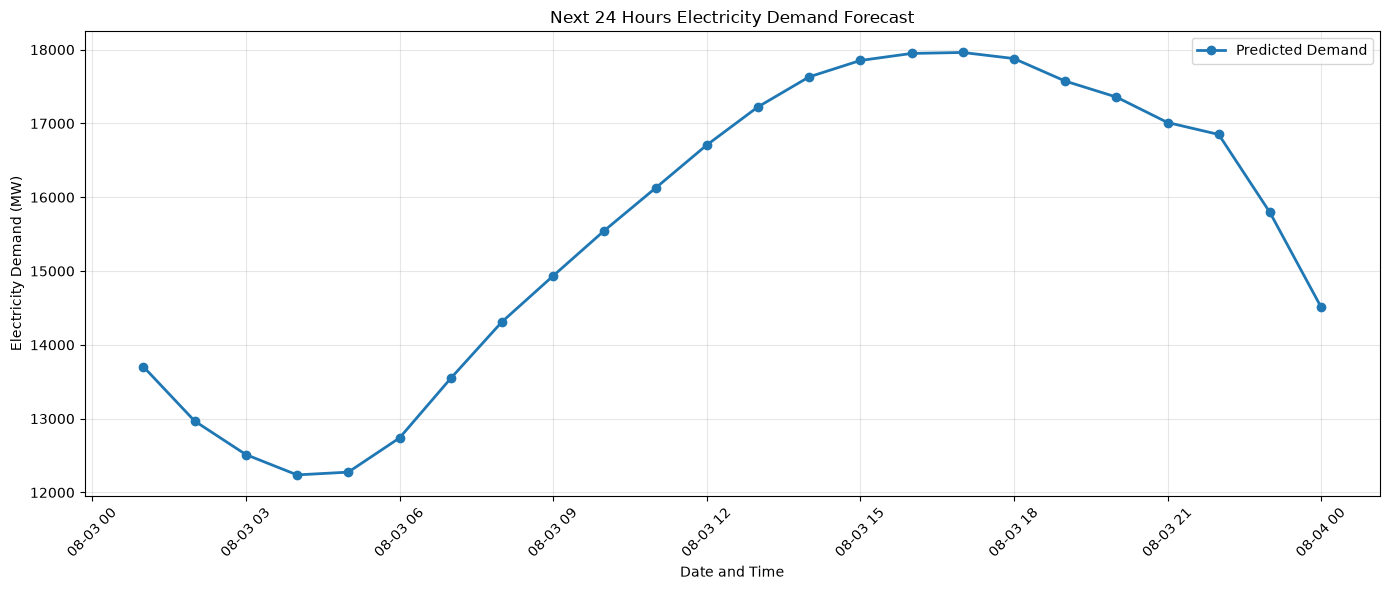

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    forecast_df["Datetime"],
    forecast_df["Predicted_Demand"],
    marker="o",
    linewidth=2,
    label="Predicted Demand"
)

plt.title("Next 24 Hours Electricity Demand Forecast")
plt.xlabel("Date and Time")
plt.ylabel("Electricity Demand (MW)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [73]:
# Calculate demand thresholds from the training data
low_threshold = y_train_improved.quantile(0.33)
high_threshold = y_train_improved.quantile(0.66)

def classify_demand(demand):
    if demand < low_threshold:
        return "Low"
    elif demand < high_threshold:
        return "Medium"
    else:
        return "High"

forecast_df["Demand_Level"] = (
    forecast_df["Predicted_Demand"].apply(classify_demand)
)

display(forecast_df)

,Datetime,Predicted_Demand,Demand_Level
0,2018-08-03 01:00:00,13702.768349,Low
1,2018-08-03 02:00:00,12967.472466,Low
2,2018-08-03 03:00:00,12513.248222,Low
3,2018-08-03 04:00:00,12238.026871,Low
4,2018-08-03 05:00:00,12275.388854,Low
5,2018-08-03 06:00:00,12738.404388,Low
6,2018-08-03 07:00:00,13545.643038,Low
7,2018-08-03 08:00:00,14311.173691,Low
8,2018-08-03 09:00:00,14934.130177,Medium
9,2018-08-03 10:00:00,15547.699855,Medium


In [74]:
# Extract high-demand periods
peak_hours = forecast_df[
    forecast_df["Demand_Level"] == "High"
].copy()

print("PEAK DEMAND ALERT")
print("-----------------")

if not peak_hours.empty:
    for _, row in peak_hours.iterrows():
        print(
            f"Alert: {row['Datetime']} | "
            f"Predicted Demand: {row['Predicted_Demand']:.2f} MW"
        )
else:
    print("No high-demand periods predicted.")

PEAK DEMAND ALERT
-----------------
Alert: 2018-08-03 12:00:00 | Predicted Demand: 16707.00 MW
Alert: 2018-08-03 13:00:00 | Predicted Demand: 17223.95 MW
Alert: 2018-08-03 14:00:00 | Predicted Demand: 17630.88 MW
Alert: 2018-08-03 15:00:00 | Predicted Demand: 17853.13 MW
Alert: 2018-08-03 16:00:00 | Predicted Demand: 17948.55 MW
Alert: 2018-08-03 17:00:00 | Predicted Demand: 17961.97 MW
Alert: 2018-08-03 18:00:00 | Predicted Demand: 17879.34 MW
Alert: 2018-08-03 19:00:00 | Predicted Demand: 17574.46 MW
Alert: 2018-08-03 20:00:00 | Predicted Demand: 17358.15 MW
Alert: 2018-08-03 21:00:00 | Predicted Demand: 17012.82 MW
Alert: 2018-08-03 22:00:00 | Predicted Demand: 16850.78 MW


In [75]:
max_demand = forecast_df["Predicted_Demand"].max()
min_demand = forecast_df["Predicted_Demand"].min()
avg_demand = forecast_df["Predicted_Demand"].mean()

peak_time = forecast_df.loc[
    forecast_df["Predicted_Demand"].idxmax(), "Datetime"
]

high_demand_hours = (
    forecast_df["Demand_Level"] == "High"
).sum()

print("ELECTRICITY DEMAND SUMMARY")
print("--------------------------")
print(f"Maximum Demand: {max_demand:.2f} MW")
print(f"Minimum Demand: {min_demand:.2f} MW")
print(f"Average Demand: {avg_demand:.2f} MW")
print(f"Peak Demand Time: {peak_time}")
print(f"High Demand Hours: {high_demand_hours} out of 24")

ELECTRICITY DEMAND SUMMARY
--------------------------
Maximum Demand: 17961.97 MW
Minimum Demand: 12238.03 MW
Average Demand: 15550.17 MW
Peak Demand Time: 2018-08-03 17:00:00
High Demand Hours: 11 out of 24


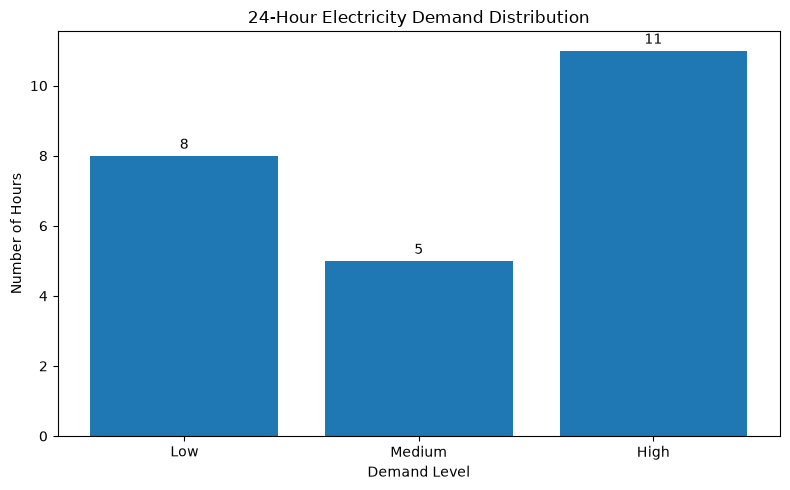

In [76]:
demand_counts = forecast_df["Demand_Level"].value_counts()

demand_counts = demand_counts.reindex(
    ["Low", "Medium", "High"],
    fill_value=0
)

plt.figure(figsize=(8, 5))

plt.bar(
    demand_counts.index,
    demand_counts.values
)

plt.title("24-Hour Electricity Demand Distribution")
plt.xlabel("Demand Level")
plt.ylabel("Number of Hours")

for i, value in enumerate(demand_counts.values):
    plt.text(i, value + 0.2, str(value), ha="center")

plt.tight_layout()
plt.show()

In [77]:
# Separate low-demand and high-demand hours
low_demand_hours = forecast_df[
    forecast_df["Demand_Level"] == "Low"
].copy()

high_demand_hours = forecast_df[
    forecast_df["Demand_Level"] == "High"
].copy()

print("LOW-DEMAND HOURS (Suggested for flexible usage)")
print("------------------------------------------------")

display(
    low_demand_hours[
        ["Datetime", "Predicted_Demand"]
    ].sort_values("Predicted_Demand")
)

print("\nHIGH-DEMAND HOURS (Potential hours to avoid shifting usage into)")
print("---------------------------------------------------------------")

display(
    high_demand_hours[
        ["Datetime", "Predicted_Demand"]
    ].sort_values("Predicted_Demand", ascending=False)
)

LOW-DEMAND HOURS (Suggested for flexible usage)
------------------------------------------------


,Datetime,Predicted_Demand
3,2018-08-03 04:00:00,12238.026871
4,2018-08-03 05:00:00,12275.388854
2,2018-08-03 03:00:00,12513.248222
5,2018-08-03 06:00:00,12738.404388
1,2018-08-03 02:00:00,12967.472466
6,2018-08-03 07:00:00,13545.643038
0,2018-08-03 01:00:00,13702.768349
7,2018-08-03 08:00:00,14311.173691



HIGH-DEMAND HOURS (Potential hours to avoid shifting usage into)
---------------------------------------------------------------


,Datetime,Predicted_Demand
16,2018-08-03 17:00:00,17961.973595
15,2018-08-03 16:00:00,17948.545987
17,2018-08-03 18:00:00,17879.337693
14,2018-08-03 15:00:00,17853.133149
13,2018-08-03 14:00:00,17630.876633
18,2018-08-03 19:00:00,17574.461377
19,2018-08-03 20:00:00,17358.153816
12,2018-08-03 13:00:00,17223.950428
20,2018-08-03 21:00:00,17012.818981
21,2018-08-03 22:00:00,16850.775459


In [78]:
recommendations = []

for _, row in high_demand_hours.iterrows():

    recommendations.append({
        "Peak_Hour": row["Datetime"],
        "Peak_Demand_MW": round(row["Predicted_Demand"], 2),
        "Recommendation": "Shift flexible electricity usage to low-demand hours"
    })

recommendation_df = pd.DataFrame(recommendations)

print("AUTOMATIC LOAD-SHIFTING RECOMMENDATIONS")
print("--------------------------------------")

display(recommendation_df)

AUTOMATIC LOAD-SHIFTING RECOMMENDATIONS
--------------------------------------


,Peak_Hour,Peak_Demand_MW,Recommendation
0,2018-08-03 12:00:00,16707.00,Shift flexible electricity usage to low-demand...
1,2018-08-03 13:00:00,17223.95,Shift flexible electricity usage to low-demand...
2,2018-08-03 14:00:00,17630.88,Shift flexible electricity usage to low-demand...
3,2018-08-03 15:00:00,17853.13,Shift flexible electricity usage to low-demand...
4,2018-08-03 16:00:00,17948.55,Shift flexible electricity usage to low-demand...
5,2018-08-03 17:00:00,17961.97,Shift flexible electricity usage to low-demand...
6,2018-08-03 18:00:00,17879.34,Shift flexible electricity usage to low-demand...
7,2018-08-03 19:00:00,17574.46,Shift flexible electricity usage to low-demand...
8,2018-08-03 20:00:00,17358.15,Shift flexible electricity usage to low-demand...
9,2018-08-03 21:00:00,17012.82,Shift flexible electricity usage to low-demand...


In [79]:
load_shift_plan = []

for _, peak in high_demand_hours.iterrows():

    best_alternative = low_demand_hours.loc[
        low_demand_hours["Predicted_Demand"].idxmin()
    ]

    load_shift_plan.append({
        "Original_Peak_Hour": peak["Datetime"],
        "Peak_Demand_MW": round(peak["Predicted_Demand"], 2),
        "Suggested_Hour": best_alternative["Datetime"],
        "Suggested_Hour_Demand_MW": round(
            best_alternative["Predicted_Demand"], 2
        )
    })

load_shift_df = pd.DataFrame(load_shift_plan)

display(load_shift_df)

,Original_Peak_Hour,Peak_Demand_MW,Suggested_Hour,Suggested_Hour_Demand_MW
0,2018-08-03 12:00:00,16707.00,2018-08-03 04:00:00,12238.03
1,2018-08-03 13:00:00,17223.95,2018-08-03 04:00:00,12238.03
2,2018-08-03 14:00:00,17630.88,2018-08-03 04:00:00,12238.03
3,2018-08-03 15:00:00,17853.13,2018-08-03 04:00:00,12238.03
4,2018-08-03 16:00:00,17948.55,2018-08-03 04:00:00,12238.03
5,2018-08-03 17:00:00,17961.97,2018-08-03 04:00:00,12238.03
6,2018-08-03 18:00:00,17879.34,2018-08-03 04:00:00,12238.03
7,2018-08-03 19:00:00,17574.46,2018-08-03 04:00:00,12238.03
8,2018-08-03 20:00:00,17358.15,2018-08-03 04:00:00,12238.03
9,2018-08-03 21:00:00,17012.82,2018-08-03 04:00:00,12238.03


In [80]:
# Sort peak hours by highest demand first
sorted_peaks = high_demand_hours.sort_values(
    "Predicted_Demand", ascending=False
).reset_index(drop=True)

# Sort low-demand hours by lowest demand first
sorted_low = low_demand_hours.sort_values(
    "Predicted_Demand"
).reset_index(drop=True)

load_shift_plan = []

for i in range(min(len(sorted_peaks), len(sorted_low))):

    peak = sorted_peaks.iloc[i]
    alternative = sorted_low.iloc[i]

    load_shift_plan.append({
        "Original_Peak_Hour": peak["Datetime"],
        "Peak_Demand_MW": round(peak["Predicted_Demand"], 2),
        "Suggested_Hour": alternative["Datetime"],
        "Suggested_Hour_Demand_MW": round(
            alternative["Predicted_Demand"], 2
        )
    })

load_shift_df = pd.DataFrame(load_shift_plan)

display(load_shift_df)

,Original_Peak_Hour,Peak_Demand_MW,Suggested_Hour,Suggested_Hour_Demand_MW
0,2018-08-03 17:00:00,17961.97,2018-08-03 04:00:00,12238.03
1,2018-08-03 16:00:00,17948.55,2018-08-03 05:00:00,12275.39
2,2018-08-03 18:00:00,17879.34,2018-08-03 03:00:00,12513.25
3,2018-08-03 15:00:00,17853.13,2018-08-03 06:00:00,12738.40
4,2018-08-03 14:00:00,17630.88,2018-08-03 02:00:00,12967.47
5,2018-08-03 19:00:00,17574.46,2018-08-03 07:00:00,13545.64
6,2018-08-03 20:00:00,17358.15,2018-08-03 01:00:00,13702.77
7,2018-08-03 13:00:00,17223.95,2018-08-03 08:00:00,14311.17


In [81]:
load_shift_df["Demand_Difference_MW"] = (
    load_shift_df["Peak_Demand_MW"]
    - load_shift_df["Suggested_Hour_Demand_MW"]
)

display(load_shift_df)

,Original_Peak_Hour,Peak_Demand_MW,Suggested_Hour,Suggested_Hour_Demand_MW,Demand_Difference_MW
0,2018-08-03 17:00:00,17961.97,2018-08-03 04:00:00,12238.03,5723.94
1,2018-08-03 16:00:00,17948.55,2018-08-03 05:00:00,12275.39,5673.16
2,2018-08-03 18:00:00,17879.34,2018-08-03 03:00:00,12513.25,5366.09
3,2018-08-03 15:00:00,17853.13,2018-08-03 06:00:00,12738.40,5114.73
4,2018-08-03 14:00:00,17630.88,2018-08-03 02:00:00,12967.47,4663.41
5,2018-08-03 19:00:00,17574.46,2018-08-03 07:00:00,13545.64,4028.82
6,2018-08-03 20:00:00,17358.15,2018-08-03 01:00:00,13702.77,3655.38
7,2018-08-03 13:00:00,17223.95,2018-08-03 08:00:00,14311.17,2912.78


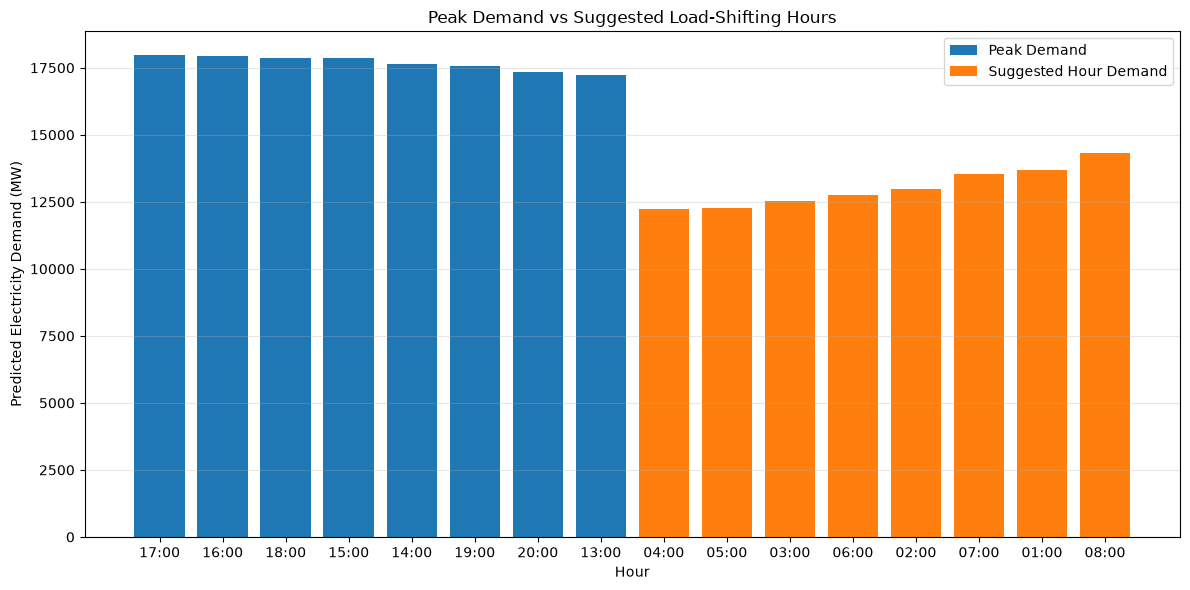

In [82]:
plt.figure(figsize=(12, 6))

plt.bar(
    load_shift_df["Original_Peak_Hour"].dt.strftime("%H:%M"),
    load_shift_df["Peak_Demand_MW"],
    label="Peak Demand"
)

plt.bar(
    load_shift_df["Suggested_Hour"].dt.strftime("%H:%M"),
    load_shift_df["Suggested_Hour_Demand_MW"],
    label="Suggested Hour Demand"
)

plt.title("Peak Demand vs Suggested Load-Shifting Hours")
plt.xlabel("Hour")
plt.ylabel("Predicted Electricity Demand (MW)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [83]:
# Save 24-hour forecast
forecast_df.to_csv(
    "next_24_hour_forecast.csv",
    index=False
)

# Save peak-demand alerts
peak_hours.to_csv(
    "peak_demand_alerts.csv",
    index=False
)

# Save load-shifting recommendations
load_shift_df.to_csv(
    "load_shifting_recommendations.csv",
    index=False
)

print("All project results exported successfully!")

All project results exported successfully!
